# Notebook 06 (Capstone Final) — Auditoría Operativa y Ambiental en Planta de Aguas Residuales
**Pungo Academy · Python y Ciencia de Datos Industrial desde Cero en Google Colab**

## Misión Integradora
Aplicar **todo lo aprendido en los Módulos 1 a 5** sobre el dataset real de la Planta de Aguas Residuales de Melbourne (**600 muestras × 15 variables**): `Heavy_Metals_mgL`, `COD_mgL`, `BOD5_mgL`, `pH`, `Energy_kWh_t`, `System_Load` y la etiqueta `Pollution_Risk`.
> **Lección clave de ingeniería de datos (Diccionario oficial):** En este dataset, **`Pollution_Risk = 0` indica Alto Riesgo Ambiental** (cuando el índice compuesto supera el percentil 65, con `35.0%` de muestras) y **`Pollution_Risk = 1` indica Operación Normal** (`65.0%` de muestras). ¡Siempre verifica qué significa `0` y `1` antes de modelar!

1. **Perfilado de Integridad (Pandas)**: verificar dimensiones, nulos y balance real `Alto Riesgo (0)` vs `Operación Normal (1)`.
2. **Función de Ingeniería (`def`) + `if/elif/else`**: regla física de cumplimiento ambiental (`pH` 6.5–8.5, `COD_mgL <= 250` mg/L, `Heavy_Metals_mgL <= 2.5` mg/L).
3. **KPIs e Hiper-segmentación (`.groupby`)**: comparar promedios en muestras de Alto Riesgo vs Operación Normal y analizar energía por cuartil de carga.
4. **Tablero Ejecutivo 2×2 (Matplotlib)**: 4 gráficos con límites ambientales claros.
5. **Modelo Base Interpretable + Reporte Exportable**: Árbol de Decisión (`max_depth=3`) con reglas exactas legibles por humanos y exportación a CSV.

In [1]:
# 1. Carga y auditoría inicial del dataset real de Planta de Aguas Residuales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, confusion_matrix

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (11.5, 5.5)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

df_ww = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_python_cero/curso_python_cero_wastewater.csv")
print("Dimensiones:", df_ww.shape, "| Nulos totales:", int(df_ww.isnull().sum().sum()))
conteo_riesgo = df_ww["Pollution_Risk"].value_counts().sort_index()
print(f"Alto Riesgo Ambiental (0): {int(conteo_riesgo[0])} ({conteo_riesgo[0]/len(df_ww)*100:.1f}%)")
print(f"Operación Normal      (1): {int(conteo_riesgo[1])} ({conteo_riesgo[1]/len(df_ww)*100:.1f}%)")
df_ww.head(5)

Dimensiones: (600, 15) | Nulos totales: 0
Alto Riesgo Ambiental (0): 210 (35.0%)
Operación Normal      (1): 390 (65.0%)


,Heavy_Metals_mgL,COD_mgL,BOD5_mgL,SS_mgL,NH3N_mgL,pH,Temp_C,Conductivity_uScm,Flow_mps,Energy_kWh_t,Prod_Load_Percent,Effluent_tph,Daily_Output_tpd,System_Load,Pollution_Risk
0,1.879,101.09,190.77,287.39,17.10,7.85,9.94,2132.4,0.46,1.30,91.86,82.35,801.13,0.43,1
1,4.754,153.72,11.02,223.88,3.68,8.29,24.98,530.8,0.30,4.84,53.79,91.48,357.48,0.50,1
2,3.663,104.97,10.42,112.44,20.54,6.38,11.48,357.6,2.74,4.79,109.79,58.07,1084.96,1.19,1
3,2.997,62.58,84.28,96.00,15.63,7.69,14.75,2410.5,0.65,1.31,89.05,122.03,313.96,0.65,1
4,0.789,77.91,124.72,111.41,33.89,7.50,12.65,314.7,2.48,1.81,52.58,80.88,1874.58,0.49,1


## Paso 2 — Regla Normativa con Funciones Python (`def` + `if/elif/else`)
Creamos una función de ingeniería para etiquetar cada descarga según límites ambientales de referencia: `pH` entre `6.5` y `8.5`, `COD_mgL <= 250.0` mg/L y `Heavy_Metals_mgL <= 2.5` mg/L.

In [2]:
# 2. Función de cumplimiento ambiental y aplicación fila a fila con .apply()
def evaluar_cumplimiento_efluente(fila):
    """Clasifica el efluente según pH, DQO (COD) y Metales Pesados."""
    ph_fuera = (fila["pH"] < 6.5) or (fila["pH"] > 8.5)
    cod_alto = fila["COD_mgL"] > 250.0
    metal_alto = fila["Heavy_Metals_mgL"] > 2.5

    infracciones = int(ph_fuera) + int(cod_alto) + int(metal_alto)
    if infracciones >= 2:
        return "CRÍTICO (2+ Excesos)"
    elif infracciones == 1:
        return "ADVERTENCIA (1 Exceso)"
    return "CONFORME"

df_ww["estado_normativo"] = df_ww.apply(evaluar_cumplimiento_efluente, axis=1)
print("=== DISTRIBUCIÓN SEGÚN REGLA NORMATIVA ===")
print(df_ww["estado_normativo"].value_counts())

print("\n=== CRUCE: ESTADO NORMATIVO vs POLLUTION_RISK (0=Alto Riesgo, 1=Normal) ===")
print(pd.crosstab(df_ww["estado_normativo"], df_ww["Pollution_Risk"]))

=== DISTRIBUCIÓN SEGÚN REGLA NORMATIVA ===
estado_normativo
CRÍTICO (2+ Excesos)      288
ADVERTENCIA (1 Exceso)    238
CONFORME                   74
Name: count, dtype: int64

=== CRUCE: ESTADO NORMATIVO vs POLLUTION_RISK (0=Alto Riesgo, 1=Normal) ===
Pollution_Risk            0    1
estado_normativo                
ADVERTENCIA (1 Exceso)   64  174
CONFORME                  1   73
CRÍTICO (2+ Excesos)    145  143


## Paso 3 — KPIs Derivados y Segmentación Operativa (`.groupby`)
Creamos una columna indicadora limpia `riesgo_alto` (`1` si `Pollution_Risk == 0`, es decir, Alto Riesgo) y comparamos los promedios físicos y energéticos entre operación normal y eventos de alto riesgo.

In [3]:
# 3. Ingeniería de KPIs y perfil comparativo (Alto Riesgo vs Operación Normal)
df_ww["ratio_bod_cod"] = (df_ww["BOD5_mgL"] / df_ww["COD_mgL"]).round(3)
df_ww["riesgo_alto"] = (df_ww["Pollution_Risk"] == 0).astype(int)

cols_resumen = [
    "COD_mgL", "BOD5_mgL", "NH3N_mgL", "Heavy_Metals_mgL",
    "pH", "Energy_kWh_t", "System_Load", "ratio_bod_cod"
]
perfil_riesgo = df_ww.groupby("Pollution_Risk")[cols_resumen].mean().round(2)
perfil_riesgo.index = ["Alto Riesgo (0)", "Operación Normal (1)"]
print("=== PERFIL PROMEDIO: ALTO RIESGO (0) vs OPERACIÓN NORMAL (1) ===")
print(perfil_riesgo.T)

# Tasa de Alto Riesgo Ambiental (%) por cuartil de carga del sistema (System_Load)
df_ww["nivel_carga"] = pd.qcut(df_ww["System_Load"], q=4, labels=["Q1 Baja", "Q2 Media-Baja", "Q3 Media-Alta", "Q4 Máxima"])
riesgo_por_carga = (df_ww.groupby("nivel_carga", observed=False)["riesgo_alto"].mean() * 100).round(1)
print("\n=== INCIDENCIA DE ALTO RIESGO (%) POR NIVEL DE CARGA ===")
print(riesgo_por_carga)

=== PERFIL PROMEDIO: ALTO RIESGO (0) vs OPERACIÓN NORMAL (1) ===
                  Alto Riesgo (0)  Operación Normal (1)
COD_mgL                    401.65                180.25
BOD5_mgL                   145.99                115.40
NH3N_mgL                    26.66                 24.55
Heavy_Metals_mgL             2.45                  2.56
pH                           7.23                  7.24
Energy_kWh_t                 2.48                  2.58
System_Load                  0.78                  0.79
ratio_bod_cod                0.39                  1.16

=== INCIDENCIA DE ALTO RIESGO (%) POR NIVEL DE CARGA ===
nivel_carga
Q1 Baja          39.1
Q2 Media-Baja    30.5
Q3 Media-Alta    35.1
Q4 Máxima        35.4
Name: riesgo_alto, dtype: float64


## Paso 4 — Tablero Ejecutivo 2×2 en Matplotlib
Construimos cuatro visualizaciones claras y accionables para presentar los hallazgos a Gerencia de Operaciones y Medio Ambiente.

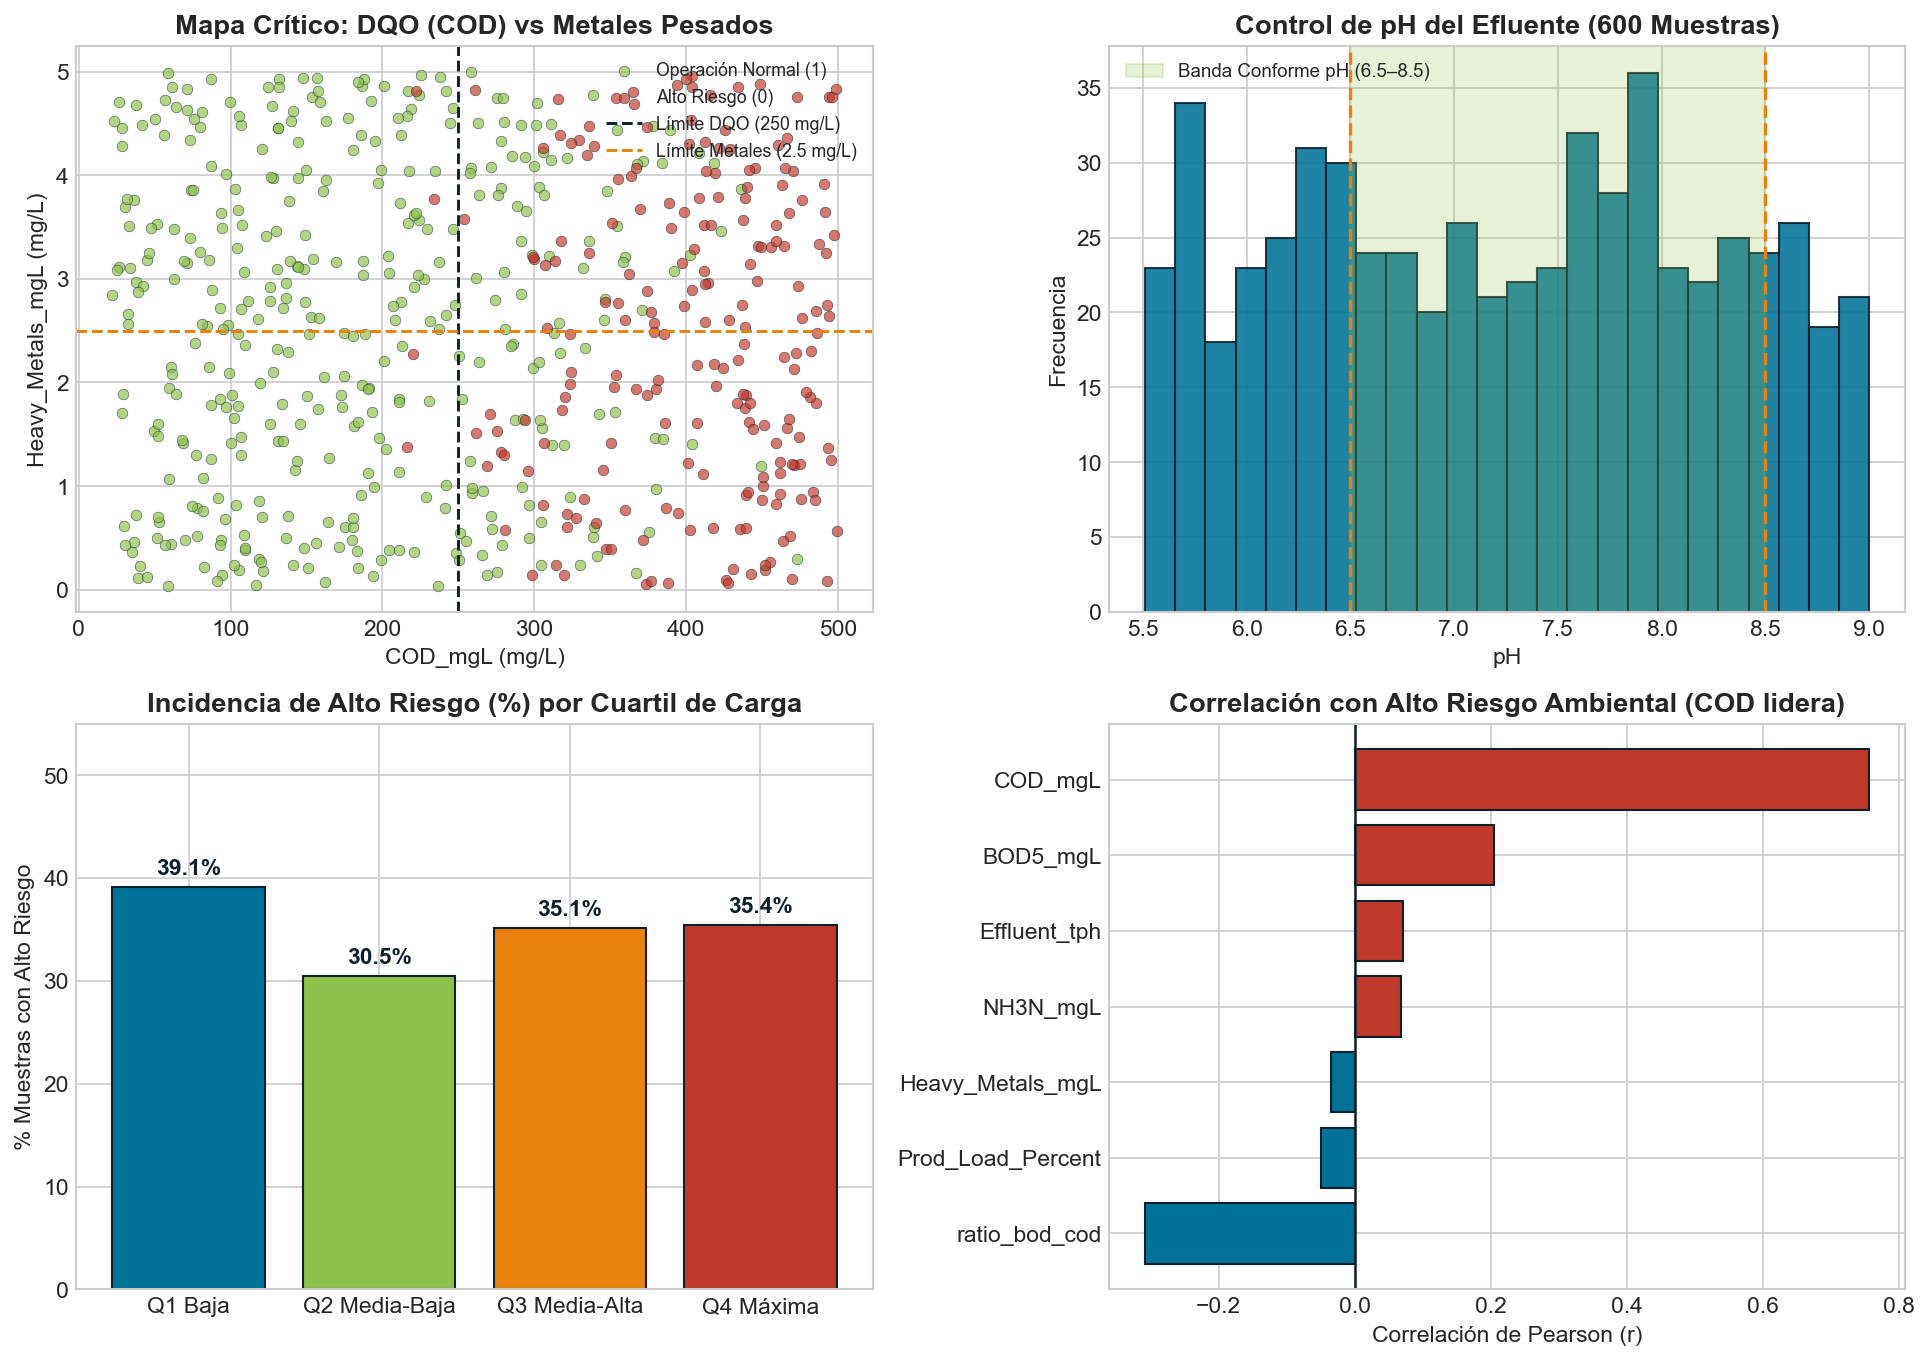

In [4]:
# 4. Tablero visual ejecutivo 2x2 de la Planta de Aguas Residuales
fig, axes = plt.subplots(2, 2, figsize=(13, 9.2))

# Panel 1: COD vs Metales Pesados coloreados por clase real (0=Alto Riesgo, 1=Normal)
for r_val, lbl, col in [(1, "Operación Normal (1)", PUNGO_LIME), (0, "Alto Riesgo (0)", PUNGO_RED)]:
    sub = df_ww[df_ww["Pollution_Risk"] == r_val]
    axes[0, 0].scatter(sub["COD_mgL"], sub["Heavy_Metals_mgL"], alpha=0.68, s=26, color=col, edgecolor=PUNGO_NAVY, linewidth=0.3, label=lbl)
axes[0, 0].axvline(250.0, color=PUNGO_NAVY, linestyle="--", linewidth=1.4, label="Límite DQO (250 mg/L)")
axes[0, 0].axhline(2.5, color=PUNGO_AMBER, linestyle="--", linewidth=1.4, label="Límite Metales (2.5 mg/L)")
axes[0, 0].set_title("Mapa Crítico: DQO (COD) vs Metales Pesados")
axes[0, 0].set_xlabel("COD_mgL (mg/L)")
axes[0, 0].set_ylabel("Heavy_Metals_mgL (mg/L)")
axes[0, 0].legend(fontsize=8.5)

# Panel 2: Distribución de pH con banda normativa 6.5-8.5
axes[0, 1].hist(df_ww["pH"], bins=24, color=PUNGO_BLUE, edgecolor=PUNGO_NAVY, alpha=0.88)
axes[0, 1].axvspan(6.5, 8.5, color=PUNGO_LIME, alpha=0.22, label="Banda Conforme pH (6.5–8.5)")
axes[0, 1].axvline(6.5, color=PUNGO_AMBER, linestyle="--", linewidth=1.6)
axes[0, 1].axvline(8.5, color=PUNGO_AMBER, linestyle="--", linewidth=1.6)
axes[0, 1].set_title("Control de pH del Efluente (600 Muestras)")
axes[0, 1].set_xlabel("pH")
axes[0, 1].set_ylabel("Frecuencia")
axes[0, 1].legend(fontsize=9)

# Panel 3: Tasa de Alto Riesgo por nivel de carga operativa
bars = axes[1, 0].bar(riesgo_por_carga.index.astype(str), riesgo_por_carga.values, color=[PUNGO_BLUE, PUNGO_LIME, PUNGO_AMBER, PUNGO_RED], edgecolor=PUNGO_NAVY)
for b in bars:
    axes[1, 0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{b.get_height():.1f}%", ha="center", fontweight="bold", color=PUNGO_NAVY)
axes[1, 0].set_ylim(0, 55)
axes[1, 0].set_title("Incidencia de Alto Riesgo (%) por Cuartil de Carga")
axes[1, 0].set_ylabel("% Muestras con Alto Riesgo")

# Panel 4: Variables más correlacionadas con Alto Riesgo Ambiental
corrs = df_ww.corr(numeric_only=True)["riesgo_alto"].drop(["riesgo_alto", "Pollution_Risk"]).sort_values()
top_corrs = pd.concat([corrs.head(3), corrs.tail(4)])
col_bars = [PUNGO_BLUE if v < 0 else PUNGO_RED for v in top_corrs.values]
axes[1, 1].barh(top_corrs.index, top_corrs.values, color=col_bars, edgecolor=PUNGO_NAVY)
axes[1, 1].axvline(0, color=PUNGO_NAVY, linewidth=1.2)
axes[1, 1].set_title("Correlación con Alto Riesgo Ambiental (COD lidera)")
axes[1, 1].set_xlabel("Correlación de Pearson (r)")

plt.tight_layout()
plt.show()

## Paso 5 — Modelo Base Interpretable (Árbol de Decisión) y Reporte Final
Cerramos el curso entrenando un **Árbol de Decisión simple (`max_depth=3`)** para predecir `riesgo_alto` (`1` = Alto Riesgo, `0` = Normal) y extraer sus **reglas exactas legibles** junto con un archivo CSV ejecutivo exportado.

In [5]:
# 5. Árbol de decisión interpretable (max_depth=3) + reglas legibles + reporte CSV
feature_cols = [
    "Heavy_Metals_mgL", "COD_mgL", "BOD5_mgL", "SS_mgL", "NH3N_mgL",
    "pH", "Temp_C", "Conductivity_uScm", "Flow_mps", "Energy_kWh_t",
    "Prod_Load_Percent", "Effluent_tph", "Daily_Output_tpd", "System_Load"
]
X_ww = df_ww[feature_cols]
y_ww = df_ww["riesgo_alto"]

X_tr, X_te, y_tr, y_te = train_test_split(X_ww, y_ww, test_size=0.20, random_state=42, stratify=y_ww)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_tr, y_tr)
preds_te = tree.predict(X_te)

acc = accuracy_score(y_te, preds_te)
cm = confusion_matrix(y_te, preds_te)
imp = pd.Series(tree.feature_importances_, index=feature_cols).sort_values(ascending=False).head(5)

print(f"Accuracy en test (n={len(X_te)}): {acc*100:.1f}%")
print("Matriz de Confusión [0=Normal, 1=Alto Riesgo]:\n", cm)
print("\nTop 5 variables determinantes:")
print(imp.round(3))

print("\nReglas explicables aprendidas por el Árbol:")
print(export_text(tree, feature_names=feature_cols))

# Exportar resumen ejecutivo por estado normativo
resumen_export = df_ww.groupby("estado_normativo")[["COD_mgL", "Heavy_Metals_mgL", "pH", "Energy_kWh_t", "riesgo_alto"]].agg(["count", "mean"]).round(2)
resumen_export.to_csv("reporte_capstone_aguas_residuales.csv")
print("Reporte exportado exitosamente -> reporte_capstone_aguas_residuales.csv")

Accuracy en test (n=120): 90.0%
Matriz de Confusión [0=Normal, 1=Alto Riesgo]:
 [[74  4]
 [ 8 34]]

Top 5 variables determinantes:
COD_mgL             0.846
BOD5_mgL            0.154
Heavy_Metals_mgL    0.000
SS_mgL              0.000
NH3N_mgL            0.000
dtype: float64

Reglas explicables aprendidas por el Árbol:
|--- COD_mgL <= 313.77
|   |--- BOD5_mgL <= 244.06
|   |   |--- COD_mgL <= 253.27
|   |   |   |--- class: 0
|   |   |--- COD_mgL >  253.27
|   |   |   |--- class: 0
|   |--- BOD5_mgL >  244.06
|   |   |--- COD_mgL <= 213.51
|   |   |   |--- class: 0
|   |   |--- COD_mgL >  213.51
|   |   |   |--- class: 1
|--- COD_mgL >  313.77
|   |--- BOD5_mgL <= 76.06
|   |   |--- COD_mgL <= 384.62
|   |   |   |--- class: 0
|   |   |--- COD_mgL >  384.62
|   |   |   |--- class: 1
|   |--- BOD5_mgL >  76.06
|   |   |--- BOD5_mgL <= 108.54
|   |   |   |--- class: 1
|   |   |--- BOD5_mgL >  108.54
|   |   |   |--- class: 1

Reporte exportado exitosamente -> reporte_capstone_aguas_residua